# 07 — Telco: Did the winner really win?
**Session 5 · Objective:** Read paired evidence, understand uncertainty, and evaluate a selection procedure within development.

Compare A = Logistic +logs and B = XGBoost +degree-2. These are complete solutions from Session 4. All calculations use Telco; the final test remains closed.

In [1]:
from pathlib import Path
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import scipy
import xgboost
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (StandardScaler, OneHotEncoder, PolynomialFeatures)
from xgboost import XGBClassifier

# Keep the actual execution environment visible alongside the results.
print({"Python": platform.python_version(), "NumPy": np.__version__,
       "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
       "SciPy": scipy.__version__, "XGBoost": xgboost.__version__})
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False,
                     "axes.spines.right": False})
from scipy.stats import wilcoxon, rankdata
from sklearn.model_selection import cross_val_score

{'Python': '3.12.9', 'NumPy': '2.5.3', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'SciPy': '1.18.1', 'XGBoost': '3.4.1'}


In [2]:
# Run from notebooks/, as in the earlier notebooks.
data_path = Path("../data/telco.csv")
fingerprint = hashlib.sha256(data_path.read_bytes()).hexdigest()
class_fingerprint = "88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a"
assert fingerprint == class_fingerprint, "Dataset differs from class; investigate before comparing figures."
print("Dataset SHA-256:", fingerprint)
df = pd.read_csv(data_path)
# Parsing is deterministic. Learned imputation stays inside the Pipeline.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].eq("Yes").astype(int)
# Preserve classroom development order, including the stable ranking tie rule.
dev, locked = train_test_split(np.arange(len(df)), test_size=0.20, stratify=y, random_state=42)
X_dev = X.iloc[dev].reset_index(drop=True)
y_dev = y.iloc[dev].reset_index(drop=True)
# Locked indices never enter fitting, scoring or decisions below.
folds = list(StratifiedKFold(5, shuffle=True, random_state=42).split(X_dev, y_dev))
assert set(dev).isdisjoint(locked)
print(f"Development: {len(dev):,}; locked final test: {len(locked):,}")

Dataset SHA-256: 88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a
Development: 5,634; locked final test: 1,409


## Rebuild both complete solutions
Original numeric variables remain present. Learned imputation, scaling and encoding are fitted inside each training partition. XGBoost uses Session 4's depth-2 configuration, not notebook 05's depth 3.

In [3]:
NUM = ["tenure", "MonthlyCharges", "TotalCharges"]

class LogFeatures(TransformerMixin, BaseEstimator):
    def __init__(self, add_logs=False):
        self.add_logs = add_logs

    def fit(self, X, y=None):
        return self  # Row-wise formulas learn no population statistics.

    def transform(self, X):
        z = X.copy()
        if self.add_logs:
            z["log_tenure"] = np.log1p(z["tenure"])
            z["log_total"] = np.log1p(z["TotalCharges"])
        return z

def build_pipeline(feature_set="raw", model="Logistic"):
    nums = NUM + (["log_tenure", "log_total"] if feature_set == "logs_only" else [])
    cats = [c for c in X_dev.columns if c not in NUM]
    numeric = Pipeline([("impute", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler())])
    branches = [("num", numeric, nums),
                ("cat", OneHotEncoder(handle_unknown="ignore"), cats)]
    if feature_set == "poly_only":
        # Add six degree-2 terms; retain the original numeric branch too.
        poly = Pipeline([("impute", SimpleImputer(strategy="median")),
                         ("scale_input", StandardScaler()),
                         ("degree2", PolynomialFeatures(degree=(2, 2), include_bias=False)),
                         ("scale_terms", StandardScaler())])
        branches.append(("poly", poly, NUM))
    classifier = (LogisticRegression(C=1, solver="lbfgs", max_iter=2000)
                  if model == "Logistic" else
                  XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=2,
                                tree_method="hist", eval_metric="logloss",
                                random_state=42, n_jobs=1))
    return Pipeline([("features", LogFeatures(feature_set == "logs_only")),
                     ("preprocess", ColumnTransformer(branches, remainder="drop")),
                     ("model", classifier)])

In [4]:
candidates = {"A: Logistic + logs": build_pipeline("logs_only"),
              "B: XGBoost + polynomials": build_pipeline("poly_only", "XGBoost")}
fold_ap, oof = {}, {}
for name, pipe in candidates.items():
    scores = []
    predictions = np.full(len(y_dev), np.nan)
    for tr, va in folds:
        fitted = clone(pipe).fit(X_dev.iloc[tr], y_dev.iloc[tr])
        predictions[va] = fitted.predict_proba(X_dev.iloc[va])[:, 1]
        scores.append(average_precision_score(y_dev.iloc[va], predictions[va]))
    assert np.isfinite(predictions).all()
    fold_ap[name], oof[name] = np.array(scores), predictions
names = list(candidates)
a, b = (fold_ap[name] for name in names)
difference = a - b
paired = pd.DataFrame({"A AP": a, "B AP": b, "A - B": difference}, index=range(1, 6))
paired.index.name = "Shared validation fold"
display(paired.round(6))
print(f"Mean A: {a.mean():.6f}; mean B: {b.mean():.6f}; mean difference: {difference.mean():+.6f}")

,A AP,B AP,A - B
Shared validation fold,,,
1,0.652116,0.652688,-0.000572
2,0.653670,0.640339,0.013331
3,0.693201,0.700809,-0.007609
4,0.682721,0.688672,-0.005951
5,0.680908,0.678604,0.002304


Mean A: 0.672523; mean B: 0.672222; mean difference: +0.000300


## Why compare pairs?
An easy fold can raise both scores. Subtract within each shared validation fold so both solutions face the same customers. Unrelated scores from different splits mix model and split effects. A small lead in the mean can coexist with more losses than wins.

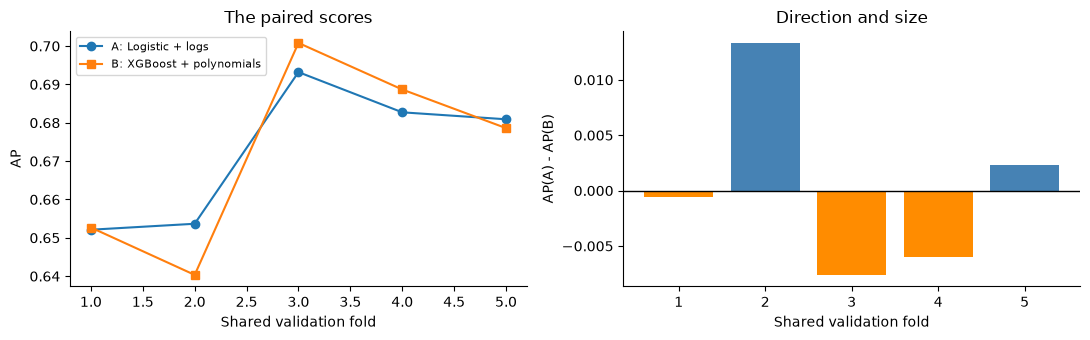

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(range(1, 6), a, "o-", label="A: Logistic + logs")
axes[0].plot(range(1, 6), b, "s-", label="B: XGBoost + polynomials")
axes[0].set(xlabel="Shared validation fold", ylabel="AP", title="The paired scores")
axes[0].legend(fontsize=8)
axes[1].bar(range(1, 6), difference, color=np.where(difference > 0, "steelblue", "darkorange"))
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set(xlabel="Shared validation fold", ylabel="AP(A) - AP(B)", title="Direction and size")
plt.tight_layout()
plt.show()

## Wilcoxon: order the sizes, then restore the signs
The signed-rank idea uses the direction and relative size of paired differences. Rank absolute nonzero differences from smallest to largest; sum ranks on either side of zero. Similar totals give little evidence of a systematic shift. Ties receive average ranks; zero differences need an explicit convention (SciPy's default drops them).

The ordinary two-sided test assumes independent paired differences with a distribution symmetric around zero under H₀. H₁ allows a systematic shift in either direction. Under these assumptions, the p-value is the probability of a signed-rank result at least as extreme as observed **if H₀ were true**. It is not the probability that H₀ is true, nor the probability that A will win next time. A 5% decision level should be set before inspecting results.

In [6]:
# Telco has five distinct, nonzero absolute differences: enumerate the exact reference.
assert np.all(difference != 0)
assert len(np.unique(np.abs(difference))) == len(difference)
ranks = rankdata(np.abs(difference))
rank_table = paired.assign(**{"Absolute difference": np.abs(difference),
                              "Rank": ranks, "Signed rank": np.sign(difference) * ranks})
display(rank_table.round(6))
pos = ranks[difference > 0].sum()
neg = ranks[difference < 0].sum()
illustrative_test = wilcoxon(difference, alternative="two-sided", method="exact")
print(f"Positive ranks: {pos:g}; negative ranks: {neg:g}")
print(f"Illustrative ordinary Wilcoxon: W={illustrative_test.statistic:g}, p={illustrative_test.pvalue:.3f}")

,A AP,B AP,A - B,Absolute difference,Rank,Signed rank
Shared validation fold,,,,,,
1,0.652116,0.652688,-0.000572,0.000572,1.0,-1.0
2,0.653670,0.640339,0.013331,0.013331,5.0,5.0
3,0.693201,0.700809,-0.007609,0.007609,4.0,-4.0
4,0.682721,0.688672,-0.005951,0.005951,3.0,-3.0
5,0.680908,0.678604,0.002304,0.002304,2.0,2.0


Positive ranks: 7; negative ranks: 8
Illustrative ordinary Wilcoxon: W=7, p=1.000


### What can this calculation support?
The class figures have rank totals **7 and 8**, W = 7 and p = **1.000**. The paired mean AP gap is only about **+0.000300** in A's favour.

Each comparison is paired, but the five training sets overlap. The differences are therefore not independent replications. Ordinary Wilcoxon on these folds is an **illustration**, not a calibrated, conclusive superiority test. Five pairs also provide very coarse evidence. Failing to reject H₀ does not demonstrate equivalence. Equivalence requires a practically meaningful margin and a suitable design and analysis.

Fold standard deviation describes variation across folds; it is neither a confidence interval for the mean nor an interval for the paired advantage.

## The customers can change even when predictions stay fixed
Pool the out-of-fold predictions. Every row was scored by a model trained without that row. Pooled OOF AP differs from mean fold AP because AP is nonlinear and pooled rankings compare scores from different fitted models.

For an exploratory **paired bootstrap**, draw customer rows with replacement. Carry each label and both scores together and recompute both APs. Some customers repeat; others disappear. Do not resample the models independently. This approximates evaluation-sample variation conditional on already fitted predictions; it does not refit or repeat selection.

Pooled OOF AP gap: +0.002149
Exploratory paired percentile interval: [-0.004754, +0.009099]


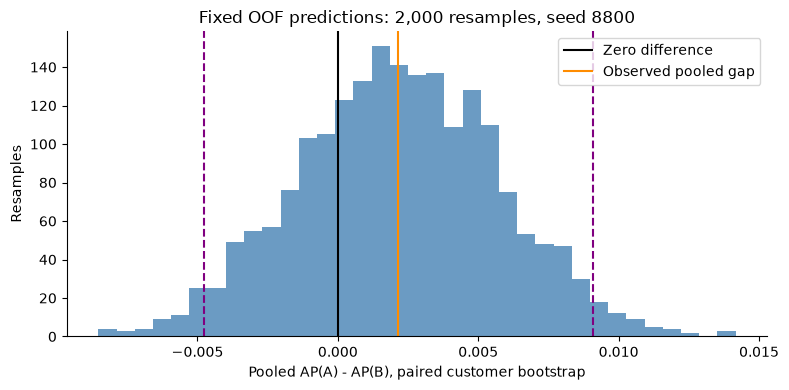

In [7]:
labels = y_dev.to_numpy()
score_a, score_b = (oof[name] for name in names)
pooled_gap = average_precision_score(labels, score_a) - average_precision_score(labels, score_b)
rng = np.random.default_rng(8800)
bootstrap_ap = np.empty(2000)
for draw in range(len(bootstrap_ap)):
    ix = rng.integers(0, len(labels), len(labels))
    bootstrap_ap[draw] = (average_precision_score(labels[ix], score_a[ix])
                          - average_precision_score(labels[ix], score_b[ix]))
lo, hi = np.quantile(bootstrap_ap, [0.025, 0.975])
print(f"Pooled OOF AP gap: {pooled_gap:+.6f}")
print(f"Exploratory paired percentile interval: [{lo:+.6f}, {hi:+.6f}]")
plt.hist(bootstrap_ap, bins=35, color="steelblue", alpha=0.8)
plt.axvline(0, color="black", label="Zero difference")
plt.axvline(pooled_gap, color="darkorange", label="Observed pooled gap")
for bound in (lo, hi):
    plt.axvline(bound, color="purple", linestyle="--")
plt.xlabel("Pooled AP(A) - AP(B), paired customer bootstrap")
plt.ylabel("Resamples")
plt.title("Fixed OOF predictions: 2,000 resamples, seed 8800")
plt.legend()
plt.tight_layout()
plt.show()

### Read the interval carefully
Percentile endpoints retain the central 95% of bootstrap differences. A wide interval means the estimate is uncertain, even if its centre is positive. Crossing zero is compatible with advantages in either direction; it does not prove equality. A confidence procedure is judged by coverage over repeated samples, rather than a 95% probability assigned to a fixed parameter after observing this interval.

This is exploratory development evidence: OOF models share training rows, score scales may differ across folds, and candidates were chosen after earlier experiments. The interval omits full uncertainty from retraining and selection. More bootstrap draws reduce Monte Carlo noise in endpoints; they do not create more independent customers.

## What changes when we try many candidates?
Session 4 examined eight representations for each of two algorithms and three encodings. These comparisons share data and are correlated. Reusing the best validation score as an unbiased performance estimate rewards useful signal and favourable noise.

At a per-comparison level of 5%, the chance of at least one false rejection among *independent true nulls* is `1 - 0.95**m`. This illustrates multiplicity, not an estimate for correlated Telco experiments. Bonferroni controls family-wise error at level α using α/m for valid tests; Holm is less conservative. Such adjustments cannot repair dependence assumptions violated by an ordinary fold-level Wilcoxon or account for unrecorded searches. Predeclare a small candidate set, record the search, and evaluate the selection procedure.

In [8]:
# Counts refer to representation comparisons considered on Telco.
# The independence assumption below is illustrative, not measured Telco evidence.
counts = np.array([1, 2, 8, 16])
display(pd.DataFrame({"Comparisons": counts,
                      "At least one false rejection (independent nulls)": 1 - 0.95**counts,
                      "Bonferroni per-test level": 0.05/counts}).round(4))

,Comparisons,At least one false rejection (independent nulls),Bonferroni per-test level
0,1,0.0500,0.0500
1,2,0.0975,0.0250
2,8,0.3366,0.0062
3,16,0.5599,0.0031


## Nested CV: choose inside, check outside
Training fits a Pipeline. Inner validation chooses candidates. Outer validation checks the **selection procedure**, using customers excluded from every inner fit and decision. Repeat within development; the final 20% test is still separate.

We actually execute five outer folds, each containing five shuffled stratified inner folds (seed 42). Reuse identical inner folds for A and B and maximize mean AP. Refit the selected Pipeline on outer training rows, then score only outer validation. Do not use outer outcomes to change the search space, contact policy or transformations.

This procedure chooses between two fixed classroom solutions. They were already explored on development data, so this is a worked nested-CV application with selection history, not a pristine confirmation of a newly preregistered search. It estimates this restricted procedure, not every experiment tried during the course.

In [9]:
nested_rows = []
for outer_fold, (tr, va) in enumerate(folds, 1):
    X_train, y_train = X_dev.iloc[tr], y_dev.iloc[tr]
    inner_folds = list(StratifiedKFold(5, shuffle=True, random_state=42).split(X_train, y_train))
    inner_means = {}
    for name, pipe in candidates.items():
        inner_means[name] = cross_val_score(clone(pipe), X_train, y_train,
                                            cv=inner_folds, scoring="average_precision").mean()
    # Dictionary order gives a deterministic tie rule: A before B.
    selected = max(inner_means, key=inner_means.get)
    fitted = clone(candidates[selected]).fit(X_train, y_train)
    p = fitted.predict_proba(X_dev.iloc[va])[:, 1]
    nested_rows.append({"Outer fold": outer_fold, "Selected inside": selected,
                        **{f"Inner mean {name}": value for name, value in inner_means.items()},
                        "Outer validation AP": average_precision_score(y_dev.iloc[va], p)})
nested = pd.DataFrame(nested_rows).set_index("Outer fold")
display(nested.round(6))
outer_scores = nested["Outer validation AP"]
print(f"Selection procedure outer AP: {outer_scores.mean():.6f}; fold std: {outer_scores.std(ddof=1):.6f}")

,Selected inside,Inner mean A: Logistic + logs,Inner mean B: XGBoost + polynomials,Outer validation AP
Outer fold,,,,
1,A: Logistic + logs,0.678064,0.673696,0.652116
2,A: Logistic + logs,0.679845,0.673100,0.653670
3,A: Logistic + logs,0.669511,0.659398,0.693201
4,A: Logistic + logs,0.671688,0.664716,0.682721
5,A: Logistic + logs,0.672063,0.670820,0.680908


Selection procedure outer AP: 0.672523; fold std: 0.018532


## Evidence, practical importance, and the decision
The nested table contains calculated outer validation results. Its mean evaluates the restricted selection procedure within development; it is not a final-test result or an automatic replacement for that test. Outer training sets overlap, so their standard deviation is descriptive. To choose a final candidate later, apply the declared inner selection procedure to all development rows, refit there, then use the final test once under a fixed evaluation plan.

Statistical evidence asks how much uncertainty surrounds a difference. Practical importance asks whether its size justifies complexity and operating cost. Business value needs an action policy and economic assumptions. A tiny AP lead does not automatically justify a more complex solution; AP cannot be converted directly into euros.

Notebook 08 asks a separate question: does adding logs to **Logistic Regression** improve expected value at fixed contact capacity? Both models there use Logistic Regression; this A-versus-B AP comparison is not the economic comparison.

**Takeaway:** Pair comparable measurements, show uncertainty, include the search in evaluation, and keep the final test closed.

Implementation references: [SciPy Wilcoxon](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wilcoxon.html) and [scikit-learn nested CV documentation](https://scikit-learn.org/stable/modules/cross_validation.html#nested-vs-non-nested-cross-validation).